# Исследование объявлений о продаже квартир

**Описание проекта**

В вашем распоряжении данные сервиса Яндекс.Недвижимость — архив объявлений о продаже квартир в Санкт-Петербурге и соседних населённых пунктов за несколько лет. Нужно научиться определять рыночную стоимость объектов недвижимости. Ваша задача — установить параметры. Это позволит построить автоматизированную систему: она отследит аномалии и мошенническую деятельность. 

**Цель проекта** — выполнить предобработку данных и изучить их, чтобы найти интересные особенности и зависимости, которые существуют на рынке недвижимости.

По каждой квартире на продажу доступны два вида данных. Первые вписаны пользователем, вторые — получены автоматически на основе картографических данных. Например, расстояние до центра, аэропорта, ближайшего парка и водоёма. 

**Описание данных**
* `airports_nearest` — расстояние до ближайшего аэропорта в метрах (м)
* `balcony` — число балконов
* `ceiling_height` — высота потолков (м)
* `cityCenters_nearest` — расстояние до центра города (м)
* `days_exposition` — сколько дней было размещено объявление (от публикации до снятия)
* `first_day_exposition` — дата публикации
* `floor` — этаж
* `floors_total` — всего этажей в доме
* `is_apartment` — апартаменты (булев тип)
* `kitchen_area` — площадь кухни в квадратных метрах (м²)
* `last_price` — цена на момент снятия с публикации
* `living_area` — жилая площадь в квадратных метрах (м²)
* `locality_name` — название населённого пункта
* `open_plan` — свободная планировка (булев тип)
* `parks_around3000` — число парков в радиусе 3 км
* `parks_nearest` — расстояние до ближайшего парка (м)
* `ponds_around3000` — число водоёмов в радиусе 3 км
* `ponds_nearest` — расстояние до ближайшего водоёма (м)
* `rooms` — число комнат
* `studio` — квартира-студия (булев тип)
* `total_area` — общая площадь квартиры в квадратных метрах (м²)
* `total_images` — число фотографий квартиры в объявлении

**План работы**

1. Предобработка данных
    * обработка пропущенных значений
    * изменение типа данных в столбцах
    * обработка дубликатов и аномальных значений
    * добавление новых столбцов
    
    
2. Исследовательский анализ данных
    * изучение продолжительности продажи квартиры
    * какие факторы влияют на общую (полную) стоимость объекта
    * какие населённые пункты с самой высокой и низкой стоимостью квадратного метра
    * как стоимость объектов зависит от расстояния до центра города


3. Вывод 

### Откройте файл с данными и изучите общую информацию. 

In [1]:
import pandas as pd
data = pd.read_csv('/datasets/real_estate_data.csv', sep = '\t')
# разделяем колонки знаком табуляции \t

In [2]:
# выведим первые 20 строчек датафрейма
data.head(20)

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
0,20,13000000.0,108.00,2019-03-07T00:00:00,3,2.70,16.0,51.00,8,NaN,...,25.00,NaN,Санкт-Петербург,18863.0,16028.0,1.0,482.0,2.0,755.0,NaN
1,7,3350000.0,40.40,2018-12-04T00:00:00,1,NaN,11.0,18.60,1,NaN,...,11.00,2.0,посёлок Шушары,12817.0,18603.0,0.0,NaN,0.0,NaN,81.0
2,10,5196000.0,56.00,2015-08-20T00:00:00,2,NaN,5.0,34.30,4,NaN,...,8.30,0.0,Санкт-Петербург,21741.0,13933.0,1.0,90.0,2.0,574.0,558.0
3,0,64900000.0,159.00,2015-07-24T00:00:00,3,NaN,14.0,NaN,9,NaN,...,NaN,0.0,Санкт-Петербург,28098.0,6800.0,2.0,84.0,3.0,234.0,424.0
4,2,10000000.0,100.00,2018-06-19T00:00:00,2,3.03,14.0,32.00,13,NaN,...,41.00,NaN,Санкт-Петербург,31856.0,8098.0,2.0,112.0,1.0,48.0,121.0
5,10,2890000.0,30.40,2018-09-10T00:00:00,1,NaN,12.0,14.40,5,NaN,...,9.10,NaN,городской посёлок Янино-1,NaN,NaN,NaN,NaN,NaN,NaN,55.0
6,6,3700000.0,37.30,2017-11-02T00:00:00,1,NaN,26.0,10.60,6,NaN,...,14.40,1.0,посёлок Парголово,52996.0,19143.0,0.0,NaN,0.0,NaN,155.0
7,5,7915000.0,71.60,2019-04-18T00:00:00,2,NaN,24.0,NaN,22,NaN,...,18.90,2.0,Санкт-Петербург,23982.0,11634.0,0.0,NaN,0.0,NaN,NaN
8,20,2900000.0,33.16,2018-05-23T00:00:00,1,NaN,27.0,15.43,26,NaN,...,8.81,NaN,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,189.0
9,18,5400000.0,61.00,2017-02-26T00:00:00,3,2.50,9.0,43.60,7,NaN,...,6.50,2.0,Санкт-Петербург,50898.0,15008.0,0.0,NaN,0.0,NaN,289.0


In [3]:
# выведим основную информацию о датафрейме
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23699 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   total_images          23699 non-null  int64  
 1   last_price            23699 non-null  float64
 2   total_area            23699 non-null  float64
 3   first_day_exposition  23699 non-null  object 
 4   rooms                 23699 non-null  int64  
 5   ceiling_height        14504 non-null  float64
 6   floors_total          23613 non-null  float64
 7   living_area           21796 non-null  float64
 8   floor                 23699 non-null  int64  
 9   is_apartment          2775 non-null   object 
 10  studio                23699 non-null  bool   
 11  open_plan             23699 non-null  bool   
 12  kitchen_area          21421 non-null  float64
 13  balcony               12180 non-null  float64
 14  locality_name         23650 non-null  object 
 15  airports_nearest   

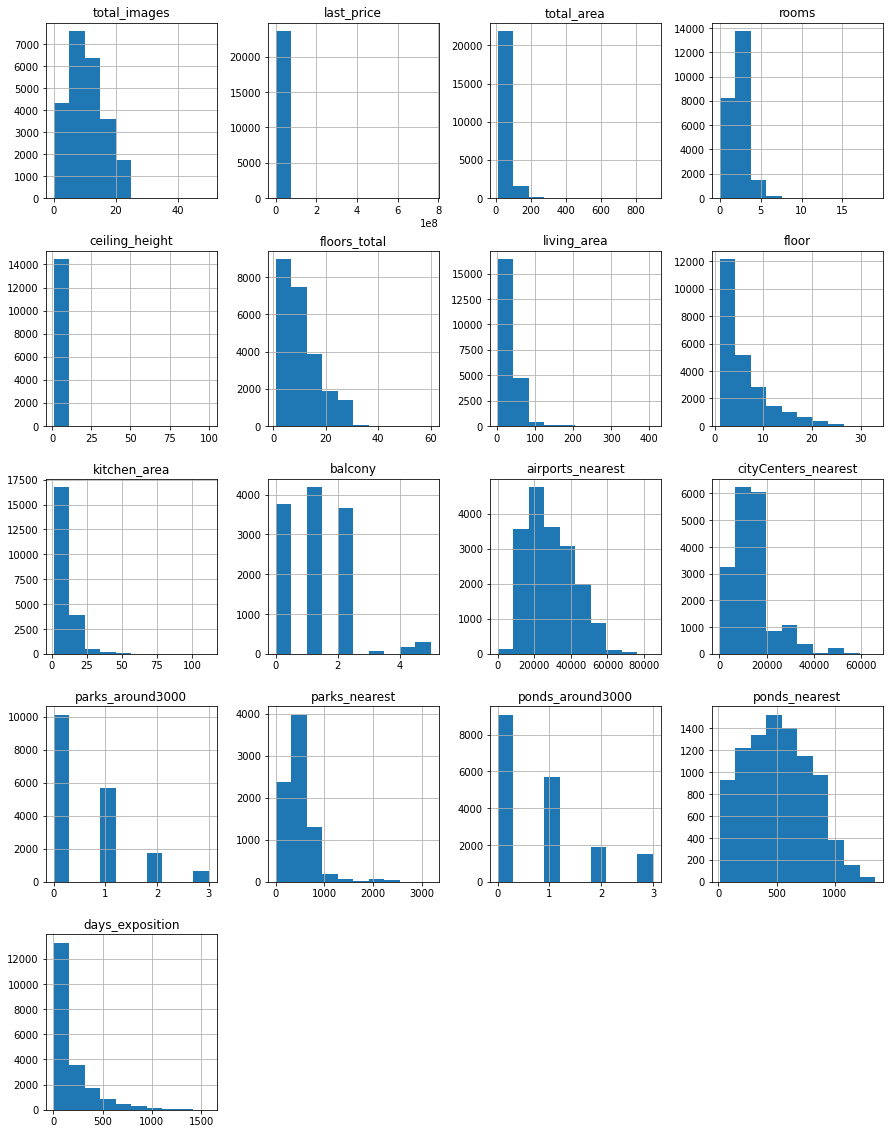

In [4]:
# строим общую гистограмму для всех числовых столбцов таблицы
data.hist(figsize=(15, 20));

**Вывод**

Всего в файле 23699 записи. В датасете видны пропущенные значения в ряде столбцов, а также некорректный тип данных. Наблюдаются аномальные значения.

### Предобработка данных

**2.1 Найдите и изучите пропущенные значения в столбцах**

In [5]:
# смотрим кол-во пропущенных значений
data.isna().sum()

total_images                0
last_price                  0
total_area                  0
first_day_exposition        0
rooms                       0
ceiling_height           9195
floors_total               86
living_area              1903
floor                       0
is_apartment            20924
studio                      0
open_plan                   0
kitchen_area             2278
balcony                 11519
locality_name              49
airports_nearest         5542
cityCenters_nearest      5519
parks_around3000         5518
parks_nearest           15620
ponds_around3000         5518
ponds_nearest           14589
days_exposition          3181
dtype: int64

В 14 столбцах есть пропущенные значения: 
* `ceiling_height` — высота потолков (м)
* `floors_total` — всего этажей в доме
* `living_area` — жилая площадь в квадратных метрах (м²)
* `is_apartment` — апартаменты (булев тип)
* `kitchen_area` — площадь кухни в квадратных метрах (м²)
* `balcony` — число балконов
* `locality_name` — название населённого пункта
* `airports_nearest` — расстояние до ближайшего аэропорта в метрах (м)
* `cityCenters_nearest` — расстояние до центра города (м)
* `parks_around3000` — число парков в радиусе 3 км
* `parks_nearest` — расстояние до ближайшего парка (м)
* `ponds_around3000` — число водоёмов в радиусе 3 км
* `ponds_nearest` — расстояние до ближайшего водоёма (м)
* `days_exposition` — сколько дней было размещено объявление (от публикации до снятия)

Один из них - `balcony`. Продавец не указал число балконов, скорее всего, в его квартире их нет. Такие пропуски можем заменить на 0

In [6]:
data['balcony']=data['balcony'].fillna(value=0)

Также в столбцах `parks_around3000` и `ponds_around3000` не укзазано число пароков\водоемов в радиусе 3 км, возможно их просто нет, поэтому также эти пропуски можем заменит на 0. Стоит отметить, что в этих столбцах одинаковое кол-во пропущенных значений

In [7]:
data['parks_around3000']=data['parks_around3000'].fillna(value=0)
data['ponds_around3000']=data['ponds_around3000'].fillna(value=0)

Пропуски в столбце `locality_name` и `floors_total` не получится ничем заменить, также их кол-во небольшое, можем удалить записи, где отсутствует локация и этажность

In [8]:
data.dropna(subset=['locality_name'], inplace=True)
data.dropna(subset=['floors_total'], inplace=True)

Выясним кол-во значений в апартаментах и заменям пропуски на False

In [9]:
data['is_apartment'].value_counts()

False    2710
True       50
Name: is_apartment, dtype: int64

In [10]:
data['is_apartment'] = data['is_apartment'].fillna(value=False)

Для пустых значений в столбце `ceiling_height` логичнее взять медианное значение высоты потолков сгруппированного по этажу

In [11]:
for t in data['floors_total'].unique():
    data.loc[(data['floors_total'] == t) & (data['ceiling_height'].isna()), 'ceiling_height'] = \
    data.groupby('floors_total')['ceiling_height'].median()[t]
data['ceiling_height'].fillna(data['ceiling_height'].median(), inplace=True)

Заменяем пустые значения жилой площади и площади кухни соотношением этих средних значений к общей площади. Используем среднее, так как она практически совпадает с медианой

In [12]:
living_ratio = data['living_area'].mean() / data['total_area'].mean()
kitchen_ratio = data['kitchen_area'].mean() / data['total_area'].mean()
data['living_area'].fillna(living_ratio * data['total_area'], inplace=True)
data['kitchen_area'].fillna(kitchen_ratio * data['total_area'], inplace=True)

Кажется, что пропуски в оставшихся столбцах: `days_exposition`, `airports_nearest` , `cityCenters_nearest`, `parks_nearest` и `ponds_nearest` невозможно ничем заменить (и не логично считать по ним медиану). Для эксперимента и практики ставим маркер -1 в `days_exposition`, чтобы пустые значения легко было отличить, в остальных столбцах оставляем пропуски как есть

In [13]:
data['days_exposition'].fillna(-1, inplace=True)

In [14]:
# проверяем количество пропущенных значений
data.isna().sum()

total_images                0
last_price                  0
total_area                  0
first_day_exposition        0
rooms                       0
ceiling_height              0
floors_total                0
living_area                 0
floor                       0
is_apartment                0
studio                      0
open_plan                   0
kitchen_area                0
balcony                     0
locality_name               0
airports_nearest         5524
cityCenters_nearest      5501
parks_around3000            0
parks_nearest           15535
ponds_around3000            0
ponds_nearest           14529
days_exposition             0
dtype: int64

*Причины, которые могли привести к пропускам в данных:*

Одной из частых причин таких ошибок — человеческий фактор, но также бывают и технические причины. Пропуски в данных могут появиться разными путями. Возможно ситема сбора информации дала сбой или клиент не захотел оставлять свои данные, также пропуски оставляют умышленно, рассчитывая на автозаполнение спецсимволами.

В данном датафрейме частой причиной пропусков был человеческий фактор - продавец не указывал значения в тои или ином столбце. Где-то можно было зменить пропущенные значения 0 или медианой, где-то вовсе удалить такие строки. Также несколько столбцов пришлось оставить с пропусками или поставить маркер, так как не представлялось возможным восполнить такие пустые значения.

**2.2 Рассмотрите типы данных в каждом столбце**

In [15]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 23565 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   total_images          23565 non-null  int64  
 1   last_price            23565 non-null  float64
 2   total_area            23565 non-null  float64
 3   first_day_exposition  23565 non-null  object 
 4   rooms                 23565 non-null  int64  
 5   ceiling_height        23565 non-null  float64
 6   floors_total          23565 non-null  float64
 7   living_area           23565 non-null  float64
 8   floor                 23565 non-null  int64  
 9   is_apartment          23565 non-null  bool   
 10  studio                23565 non-null  bool   
 11  open_plan             23565 non-null  bool   
 12  kitchen_area          23565 non-null  float64
 13  balcony               23565 non-null  float64
 14  locality_name         23565 non-null  object 
 15  airports_nearest   

Некоторые столбцы разумно преобразовать к целочисленному типу (int), так как данные в них являются целым числами и количественными переменными, кроме того такой тип проще анализировать

In [16]:
data['last_price'] = data['last_price'].astype(int)
data['floors_total'] = data['floors_total'].astype(int)
data['balcony'] = data['balcony'].astype(int)
data['parks_around3000'] = data['parks_around3000'].astype(int)
data['ponds_around3000'] = data['ponds_around3000'].astype(int)

Также сразу приведем столбец дата публикации к типу даты

In [17]:
data['first_day_exposition'] = pd.to_datetime(data['first_day_exposition'], format='%Y-%m-%dT%H:%M:%S')

In [18]:
# проверям новые типы данных
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 23565 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   total_images          23565 non-null  int64         
 1   last_price            23565 non-null  int64         
 2   total_area            23565 non-null  float64       
 3   first_day_exposition  23565 non-null  datetime64[ns]
 4   rooms                 23565 non-null  int64         
 5   ceiling_height        23565 non-null  float64       
 6   floors_total          23565 non-null  int64         
 7   living_area           23565 non-null  float64       
 8   floor                 23565 non-null  int64         
 9   is_apartment          23565 non-null  bool          
 10  studio                23565 non-null  bool          
 11  open_plan             23565 non-null  bool          
 12  kitchen_area          23565 non-null  float64       
 13  balcony         

*Почему нужно изменить тип данных*

Без изменения типа данных будет сложно провести анализ этих данных. Так как неверный тип может привести к ошибке или неожиданным результатам.

**2.3 Изучите уникальные значения в столбце с названиями и устраните неявные дубликаты**

In [19]:
# проверим датасет на наличие явных дубликатов 
data.duplicated().sum()

0

Теперь изучим уникальные значения в интересующем нас столбце с названиями - `locality_name` и обработаем неявные дубликаты

In [20]:
data['locality_name'].unique()

array(['Санкт-Петербург', 'посёлок Шушары', 'городской посёлок Янино-1',
       'посёлок Парголово', 'посёлок Мурино', 'Ломоносов', 'Сертолово',
       'Петергоф', 'Пушкин', 'деревня Кудрово', 'Коммунар', 'Колпино',
       'поселок городского типа Красный Бор', 'Гатчина', 'поселок Мурино',
       'деревня Фёдоровское', 'Выборг', 'Кронштадт', 'Кировск',
       'деревня Новое Девяткино', 'посёлок Металлострой',
       'посёлок городского типа Лебяжье',
       'посёлок городского типа Сиверский', 'поселок Молодцово',
       'поселок городского типа Кузьмоловский',
       'садовое товарищество Новая Ропша', 'Павловск',
       'деревня Пикколово', 'Всеволожск', 'Волхов', 'Кингисепп',
       'Приозерск', 'Сестрорецк', 'деревня Куттузи', 'посёлок Аннино',
       'поселок городского типа Ефимовский', 'посёлок Плодовое',
       'деревня Заклинье', 'поселок Торковичи', 'поселок Первомайское',
       'Красное Село', 'посёлок Понтонный', 'Сясьстрой', 'деревня Старая',
       'деревня Лесколово', '

In [21]:
len(data['locality_name'].sort_values().unique())

364

In [22]:
# приведем все значения в столбце к нижнему регистру 
data['locality_name'] = data['locality_name'].str.lower()

In [23]:
# убираем неявные дубликаты
n= '<'.join(data['locality_name'])
n = n.replace('ё', 'е')
n = n.replace('поселок городского типа', 'поселок')
n = n.replace('городской поселок', 'поселок')
n = n.replace('коттеджный поселок', 'поселок')
n = n.replace('поселок пансионат', 'поселок')
n = n.replace('поселок при железнодорожной', 'поселок')
n = n.replace('садоводческое некоммерческое товарищество', 'садовое товарищество')
data['locality_name'] = n.split('<')

In [24]:
len(data['locality_name'].sort_values().unique())

319

Таким образом, убрали 45 неявных дубликатов в столбце и сократили наименование поселков 

**2.4 Найдите и устраните редкие и выбивающиеся значения**

Рассмотрим столбец `ceiling_height`, есть данные, где указана высота потолков выше 20 м. Логично предположить, что это вещественные значения: 2.0 м. Отфильтруем данные и разделим на 10. Также есть небольшое кол-во квартир с высотой потолков 10-20м, возможно это ошибки, поэтому исключим строки с высотой потолков более 10 м

In [25]:
data['ceiling_height'].unique()

array([  2.7 ,   2.75,   2.55,   2.6 ,   3.03,   2.65,   2.66,   2.5 ,
         2.67,   2.56,   3.  ,   3.05,   2.8 ,   2.9 ,   3.2 ,   2.61,
         3.25,   3.45,   2.77,   2.85,   2.64,   2.57,   4.15,   3.5 ,
         3.3 ,   2.71,   4.  ,   2.47,   2.73,   2.84,   3.1 ,   2.34,
         3.4 ,   3.06,   2.72,   2.54,   2.51,   2.78,   2.76,  25.  ,
         2.58,   3.7 ,  14.85,   2.52,   5.2 ,   2.87,   2.59,   2.  ,
         2.45,   3.6 ,   2.92,   3.11,   3.13,   3.8 ,   3.15,   3.55,
         3.16,   3.62,   3.12,   2.53,   2.74,   2.96,   2.46,   5.3 ,
         5.  ,   2.79,   2.95,   4.06,   2.94,   3.82,   3.54,   3.53,
         2.83,   4.7 ,   2.4 ,   3.38,   3.01,   5.6 ,   3.65,   3.9 ,
         3.18,   3.35,   2.3 ,   3.57,   2.48,   2.62,   2.82,   3.98,
         2.63,   3.83,   3.52,   3.95,   3.75,   2.88,   3.67,   3.87,
         3.66,   3.85,   3.86,   4.19,   3.24,   4.8 ,   4.5 ,   4.2 ,
         3.36,  32.  ,   3.08,   3.68,   3.07,   3.37,   3.09,   8.  ,
      

In [26]:
data.loc[data['ceiling_height'] >= 20, 'ceiling_height'] = \
data.loc[data['ceiling_height'] >= 20, 'ceiling_height'] / 10
data.loc[data['ceiling_height'] >= 10,'ceiling_height'] = None
data.loc[data['ceiling_height'] < 2,'ceiling_height'] = None
data.dropna(subset=['ceiling_height'], inplace=True)

In [27]:
# проверям результат
data['ceiling_height'].unique()

array([2.7 , 2.75, 2.55, 2.6 , 3.03, 2.65, 2.66, 2.5 , 2.67, 2.56, 3.  ,
       3.05, 2.8 , 2.9 , 3.2 , 2.61, 3.25, 3.45, 2.77, 2.85, 2.64, 2.57,
       4.15, 3.5 , 3.3 , 2.71, 4.  , 2.47, 2.73, 2.84, 3.1 , 2.34, 3.4 ,
       3.06, 2.72, 2.54, 2.51, 2.78, 2.76, 2.58, 3.7 , 2.52, 5.2 , 2.87,
       2.59, 2.  , 2.45, 3.6 , 2.92, 3.11, 3.13, 3.8 , 3.15, 3.55, 3.16,
       3.62, 3.12, 2.53, 2.74, 2.96, 2.46, 5.3 , 5.  , 2.79, 2.95, 4.06,
       2.94, 3.82, 3.54, 3.53, 2.83, 4.7 , 2.4 , 3.38, 3.01, 5.6 , 3.65,
       3.9 , 3.18, 3.35, 2.3 , 3.57, 2.48, 2.62, 2.82, 3.98, 2.63, 3.83,
       3.52, 3.95, 3.75, 2.88, 3.67, 3.87, 3.66, 3.85, 3.86, 4.19, 3.24,
       4.8 , 4.5 , 4.2 , 3.36, 3.08, 3.68, 3.07, 3.37, 3.09, 8.  , 3.26,
       3.34, 2.81, 3.44, 2.97, 3.14, 4.37, 2.68, 3.22, 3.27, 4.1 , 2.93,
       3.46, 3.47, 3.33, 3.63, 3.32, 8.3 , 2.98, 2.86, 3.17, 4.4 , 3.28,
       3.04, 4.45, 5.5 , 3.84, 3.23, 3.02, 3.21, 3.43, 3.78, 4.3 , 3.39,
       2.69, 3.31, 4.65, 3.56, 2.2 , 3.51, 3.93, 3.

Изучим столбец `floors_total`, выделяется два показателя 52 и 60 этажей. Делаем срез и смотрим, где расположены эти здания. 60 этажного дома в Кронштадте точно нет, скорее всего ошибка, заменим значение на 6

In [28]:
data['floors_total'].unique()

array([16, 11,  5, 14, 12, 26, 24, 27,  9,  6, 17, 25,  3, 23, 19, 18,  4,
       22,  8,  2, 10,  7, 13, 15, 20, 28, 21, 35, 34, 60,  1, 29, 36, 33,
       52])

<AxesSubplot:>

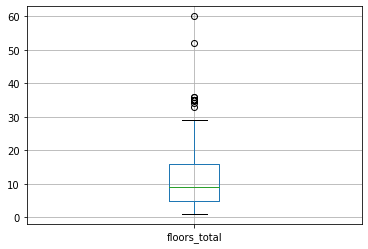

In [29]:
data.boxplot(column='floors_total')

In [30]:
data.query('floors_total == 60 or floors_total == 52')

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
2253,12,3800000,45.5,2018-06-28,2,2.88,60,27.4,4,False,...,7.4,0,кронштадт,67763.0,49488.0,2,342.0,3,614.0,166.0
16731,9,3978000,40.0,2018-09-24,1,2.65,52,10.5,18,False,...,14.0,0,санкт-петербург,20728.0,12978.0,1,793.0,0,NaN,45.0


In [31]:
data.loc[data['floors_total'] == 60, 'floors_total'] = 6

# проверяем результат
data.query('floors_total == 6 and locality_name == "кронштадт"')

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
2253,12,3800000,45.5,2018-06-28,2,2.88,6,27.4,4,False,...,7.4,0,кронштадт,67763.0,49488.0,2,342.0,3,614.0,166.0


In [32]:
# изучим корректность площадей квартир, убедимся, есть ли аномалии
data[['total_area', 'living_area', 'kitchen_area']].describe()

,total_area,living_area,kitchen_area
count,23558.000000,23558.000000,23558.000000
mean,60.327241,34.595739,10.500037
std,35.660996,22.375752,6.038262
min,12.000000,2.000000,1.300000
25%,40.000000,19.000000,7.000000
50%,52.000000,30.000000,9.000000
75%,69.700000,42.100000,12.000000
max,900.000000,409.700000,112.000000


Вроде все в порядке, оставляем без изменений. Также методом unique() были изучены столбцы с кол-во балконов, этажей и комнат - выбивающиеся значения не были выявлены

**Вывод**

В изначальном файле было 23 699 строк, в результате обработки осталось 23 558 строк, где представлялось возможным пропуски были заменены подходящим значением.

Было сделано: 
- В столбцах `balcony`, `parks_around3000` и `ponds_around3000`пропуски были заменены на 0
- Пропуски в столбцах `locality_name` и `floors_total` были исключены, как вероятные ошибки
- В столбце `is_apartment` пропуски заменили на False
- В столбце `ceiling_height` пропуски заменили на медианы значений высот потолков по каждому этажу
- Пропуски в столбцах `kitchen_area` и `living_area` заменили соотношением этих средних значений к общей площади
- Значения в остальных столбцах принято решение не обрабатывать как менее значимые для проведения данного исследования. Для практики был оставлен маркер -1 в столбце `days_exposition`.
- ряд столбцов был преобразован в целочисленный тип (int)
- все названия приведены к нижнему регистру и убраны неявные дубликаты
- обработаны аномальные значения в столбцах `ceiling_height` и `floors_total`

### Посчитайте и добавьте в таблицу новые столбцы

Цена одного квадратного метра

In [33]:
# считаем и добавляем столбец с ценой квадратного метра (price_area) 
data['price_area'] = data['last_price'] / data['total_area']

День недели публикации объявления (0 — понедельник, 1 — вторник и так далее)

In [34]:
data['weekday'] = data['first_day_exposition'].dt.weekday

Месяц публикации объявления

In [35]:
data['month'] = data['first_day_exposition'].dt.month

Год публикации объявления

In [36]:
data['year'] = data['first_day_exposition'].dt.year

Тип этажа квартиры (значения — «‎первый», «последний», «другой»)

In [37]:
def floor_group(row):
    if row['floor'] == 1:
        return 'первый'
    elif row['floor'] == row['floors_total']:
        return 'последний'
    else:
        return 'другой'
data['floor_type'] = data.apply(floor_group, axis=1)

Расстояние до центра города в километрах (переведите из м в км и округлите до целых значений)

In [38]:
data['km_cityCenters'] = (data['cityCenters_nearest'] / 1000).fillna(value=0).astype(int)

**Вывод**

В данном разделе посчитали и добавили в исходную таблицу следующие столбцы:
* цену квадратного метра;
* день недели, месяц и год публикации объявления;
* типы этажности квартиры — первый, последний, другой;
* расстояние до центра города в километрах

### Проведите исследовательский анализ данных

**4.1 Изучите основные параметры и постройте гистограммы для каждого их них**

count    23558.000000
mean        60.327241
std         35.660996
min         12.000000
25%         40.000000
50%         52.000000
75%         69.700000
max        900.000000
Name: total_area, dtype: float64

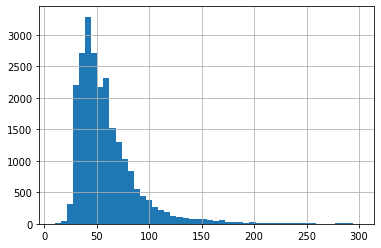

In [39]:
# общая площадь
data['total_area'].hist(bins=50, range=(10,300))
data['total_area'].describe()

<AxesSubplot:>

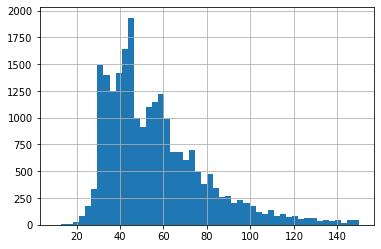

In [40]:
data['total_area'].hist(bins=50, range=(10,150))

In [41]:
# наибольшие по площади варианты 
data['total_area'].sort_values(ascending=False).head(10)

19540    900.0
12859    631.2
3117     631.0
15651    618.0
5358     590.0
4237     517.0
8018     507.0
5893     500.0
15016    500.0
12401    495.0
Name: total_area, dtype: float64

Большим спросом пользуются квартиры до 100 м2, среднее значение площади = 60,3 м2. Квартиры с большей площадью являются редкостью. В датасете есть несколько очень больших и странных вариантов с площадью более 200 м2.

count    23558.000000
mean        34.595739
std         22.375752
min          2.000000
25%         19.000000
50%         30.000000
75%         42.100000
max        409.700000
Name: living_area, dtype: float64

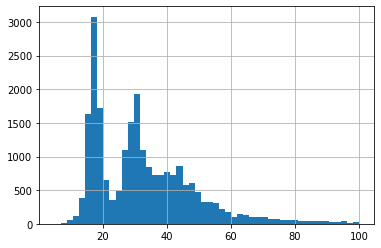

In [42]:
# жилая площадь
data['living_area'].hist(bins=50, range=(5,100))
data['living_area'].describe()

In [43]:
# наибольшие по жилой площади варианты 
data['living_area'].sort_values(ascending=False).head(10)

19540    409.700000
5358     409.000000
3117     360.410721
12401    347.500000
4237     332.000000
12859    322.300000
660      312.500000
8018     301.500000
14088    300.000000
15016    285.586942
Name: living_area, dtype: float64

Самые распространённые варианты с жилой площадью от 10 до 50 м. После 80 м встречаются единичные случаи. Два пика графика скорее всего возможно объяснить тем, что это жилые площади для квартир с разным кол-во комнат

count    23558.000000
mean        10.500037
std          6.038262
min          1.300000
25%          7.000000
50%          9.000000
75%         12.000000
max        112.000000
Name: kitchen_area, dtype: float64

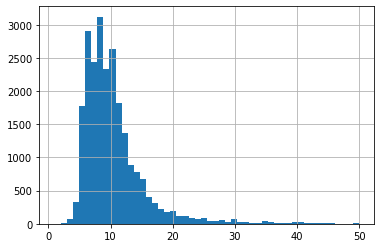

In [44]:
# площадь кухни
data['kitchen_area'].hist(bins=50, range=(1,50))
data['kitchen_area'].describe()

In [45]:
# наибольшие по площади кухни варианты
data['kitchen_area'].sort_values(ascending=False).head(10)

19540    112.000000
20215    107.000000
2489     100.700000
5358     100.000000
16239     93.200000
16797     93.000000
15016     87.537299
10867     87.200000
9826      86.504359
4394      77.000000
Name: kitchen_area, dtype: float64

Больше всего кухонь от 5 до 15 м. Больше 20 м кухни практически не встречаются и больше 30 м уже единичные случаи

count    2.355800e+04
mean     6.540155e+06
std      1.091235e+07
min      1.219000e+04
25%      3.400000e+06
50%      4.645000e+06
75%      6.790000e+06
max      7.630000e+08
Name: last_price, dtype: float64

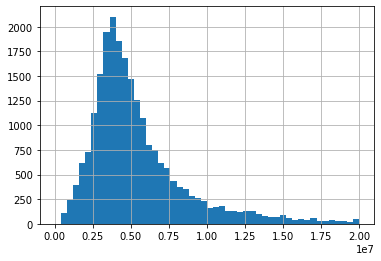

In [46]:
# цена объекта
data['last_price'].hist(bins=50, range=(0,20000000))
data['last_price'].describe()

В основном стоимость квартир от 2.5 до 6 миллионов. Больше 20 миллионов вариантов мало

count    23558.000000
mean         2.070804
std          1.078683
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         19.000000
Name: rooms, dtype: float64

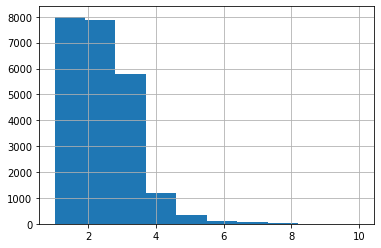

In [47]:
# кол-во комнат
data['rooms'].hist(range=(1,10))
data['rooms'].describe()

В основном квартиры состоят из 1, 2 и 3 комнат. Есть небольшая доля 4-комнатных квартир. Варианты, где больше 6 комнат редки

count    23558.000000
mean         2.708505
std          0.245300
min          2.000000
25%          2.550000
50%          2.650000
75%          2.750000
max          8.300000
Name: ceiling_height, dtype: float64

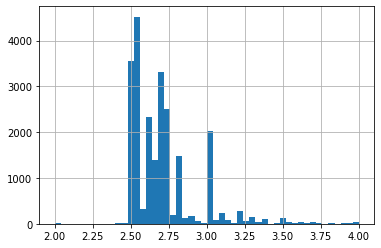

In [48]:
# высота потолков
data['ceiling_height'].hist(bins=50, range=(2, 4))
data['ceiling_height'].describe()

Самая распространенная высота потолков от 2,5 до 3 метров. Потолки от 4 до 8 метров очень редки

count    23558.000000
mean         5.877069
std          4.869595
min          1.000000
25%          2.000000
50%          4.000000
75%          8.000000
max         33.000000
Name: floor, dtype: float64

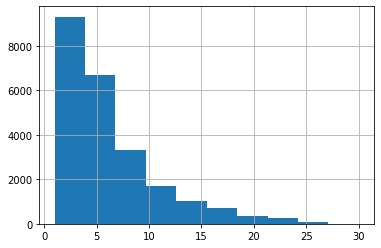

In [49]:
# этаж квартиры
data['floor'].hist(bins=10, range=(1, 30))
data['floor'].describe()

Больше всего объектов расположено с 1 по 8 этаж. Квартиры выше 20 этажа малочислены

<AxesSubplot:>

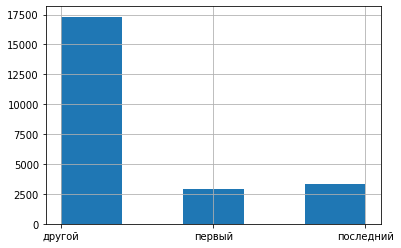

In [50]:
# тип этажа квартиры
data['floor_type'].hist(bins=5)

Больше всего квартир расположено между первыми и последними этажами

count    23558.000000
mean        10.671577
std          6.583259
min          1.000000
25%          5.000000
50%          9.000000
75%         16.000000
max         52.000000
Name: floors_total, dtype: float64

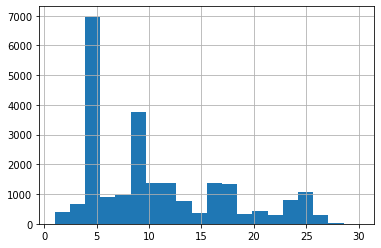

In [51]:
# общее количество этажей в доме
data['floors_total'].hist(bins=20, range=(1, 30))
data['floors_total'].describe()

В основном квартиры расположены в 5-ти и 9-ти этажных домах, намного реже в высотных домах от 17 этажей

count    18058.000000
mean     14192.446838
std       8614.398111
min        181.000000
25%       9238.000000
50%      13095.000000
75%      16285.000000
max      65968.000000
Name: cityCenters_nearest, dtype: float64

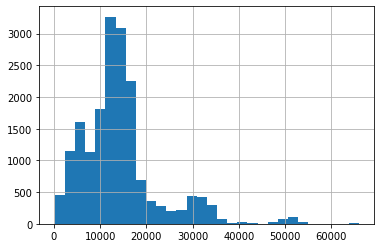

In [52]:
# расстояние до центра города в метрах
data['cityCenters_nearest'].hist(bins=30)
data['cityCenters_nearest'].describe()

Большинство квартир расположено в районе 10-20 км от центра города, очень редко дальше 40 км  

count    18035.000000
mean     28797.977377
std      12633.478792
min          0.000000
25%      18561.000000
50%      26757.000000
75%      37274.000000
max      84869.000000
Name: airports_nearest, dtype: float64

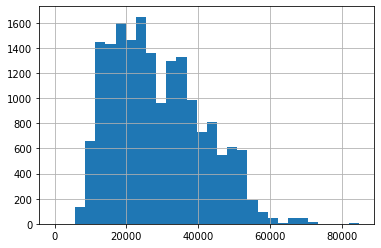

In [53]:
# расстояние до ближайшего аэропорта
data['airports_nearest'].hist(bins=30)
data['airports_nearest'].describe()

В основном расстояние объектов до ближайшего аэропорта соствляет от 15 до 40 км, дальше 60 км - единичные случаи 

count    8027.000000
mean      490.644699
std       341.616139
min         1.000000
25%       288.000000
50%       455.000000
75%       612.000000
max      3190.000000
Name: parks_nearest, dtype: float64

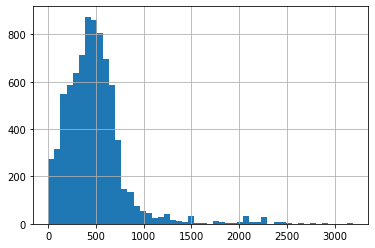

In [54]:
# расстояние до ближайшего парка
data['parks_nearest'].hist(bins=50)
data['parks_nearest'].describe()

Чаще всего объекты расположены около 500 метров до ближайшего парка, единичные случаи - от 1 км

array([[<AxesSubplot:title={'center':'weekday'}>,
        <AxesSubplot:title={'center':'month'}>]], dtype=object)

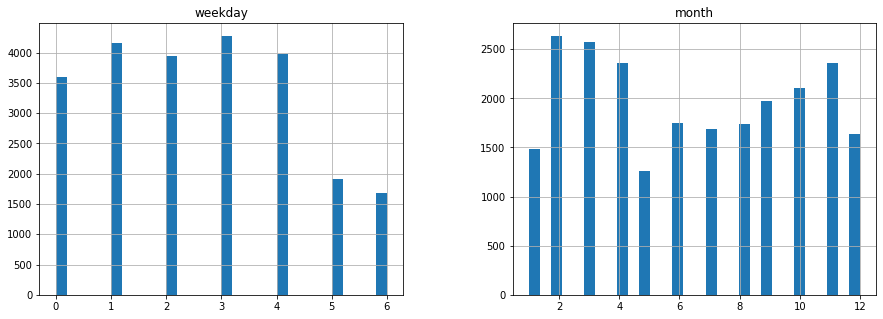

In [55]:
# день и месяц публикации объявления
data[['weekday', 'month']].hist(figsize = (15,5), bins=30)

В основном объявления публикуют со вторника по пятницу, в феврале и марте. Провисают летние и месяцы с большим кол-во праздничных дней (май, декабрь и январь) 

**4.2 Изучите, как быстро продавались квартиры**

Среднее: 181.0
Медиана: 95.0


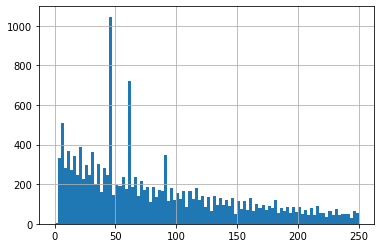

In [56]:
data.query('days_exposition != -1')['days_exposition'].hist(bins=100, range=(0,250))
# отбрасываем маркеры пустых значений и считаем среднюю и медиану
print('Среднее:', data.query('days_exposition != -1')['days_exposition'].mean().round())
print('Медиана:', data.query('days_exposition != -1')['days_exposition'].median().round())

In [57]:
data.query('days_exposition != -1')['days_exposition'].describe()

count    20387.000000
mean       180.763575
std        219.757144
min          1.000000
25%         45.000000
50%         95.000000
75%        231.000000
max       1580.000000
Name: days_exposition, dtype: float64

Среднее время продажи - 181 день. Медианное время продажи - 95 дней.

Обычно квартиры продаются за срок в 100 дней (3 месяца). Самыми быстрыми продажами можно считать срок в 45 дней и меньше, долгой - 230 дней (7,5 месяца) и дольше.

**4.3 Какие факторы больше всего влияют на общую (полную) стоимость объекта?**

Корреляция цены и общей площади: 0.6536730679721106


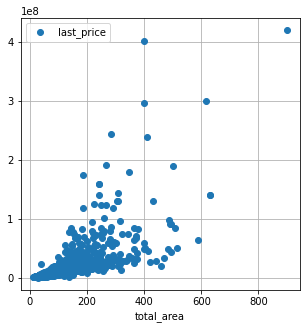

In [58]:
# зависимость цены от общей площади
(
    data.pivot_table(index='total_area', values='last_price')
    .plot(grid=True, style='o', figsize=(5, 5))
)

print('Корреляция цены и общей площади:', \
      data['last_price'].corr(data['total_area']))

Корреляция цены и жилой площади: 0.5857346684104465


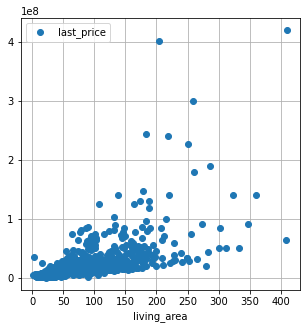

In [59]:
# зависимость цены от жилой площади
(
    data.pivot_table(index='living_area', values='last_price')
    .plot(grid=True, style='o', figsize=(5, 5))
)

print('Корреляция цены и жилой площади:', \
      data['last_price'].corr(data['living_area']))

Корреляция цены и площади кухни: 0.5145497254728442


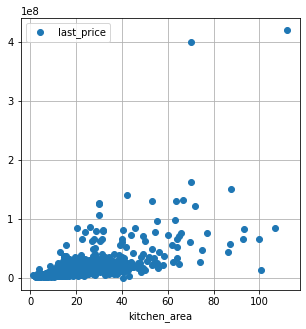

In [60]:
# зависимость цены от площади кухни
(
    data.pivot_table(index='kitchen_area', values='last_price')
    .plot(grid=True, style='o', figsize=(5, 5))
)

print('Корреляция цены и площади кухни:', \
      data['last_price'].corr(data['kitchen_area']))

Корреляция цены и количества комнат: 0.3632369784738164


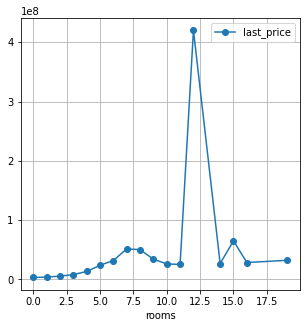

In [61]:
# зависимость цены от количества комнат
(
    data.pivot_table(index='rooms', values='last_price')
    .plot(grid=True, style='o-', figsize=(5, 5))
)

print('Корреляция цены и количества комнат:', \
      data['last_price'].corr(data['rooms']))

<AxesSubplot:xlabel='floor_type'>

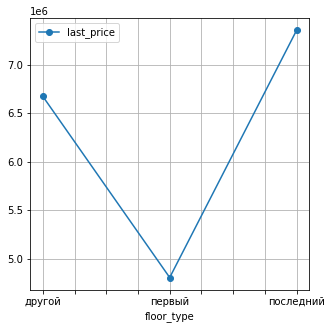

In [62]:
# зависимость цены от этажа, на котором расположена квартира (первый, последний, другой)
(
    data.pivot_table(index='floor_type', values='last_price')
    .plot(grid=True, style='o-', figsize=(5, 5))
)

<AxesSubplot:xlabel='floor_type'>

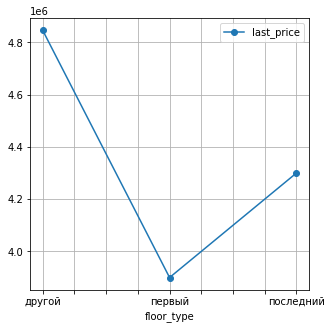

In [63]:
(
    data.pivot_table(index='floor_type', values='last_price', aggfunc='median')
    .plot(grid=True, style='o-', figsize=(5, 5))
)

Корреляция цены и даты размещения (день недели): 0.001340424400032931
Корреляция цены и даты размещения (месяц): 0.0027415556009616456
Корреляция цены и даты размещения (год): -0.04289394276097801


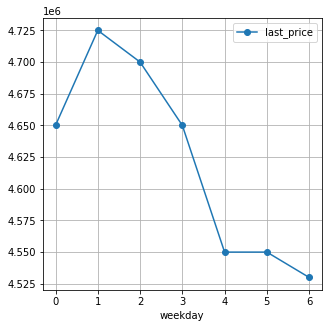

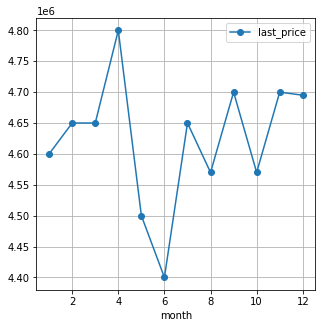

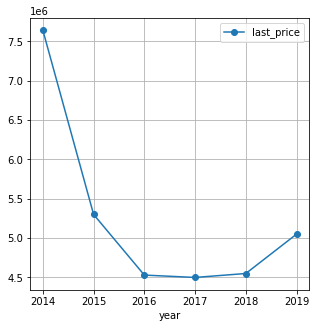

In [64]:
# зависимость цены от даты размещения (день недели)
(
    data.pivot_table(index='weekday', values='last_price',aggfunc='median')
    .plot(grid=True, style='o-', figsize=(5, 5))
)
print('Корреляция цены и даты размещения (день недели):', \
      data['last_price'].corr(data['weekday']))

# зависимость цены от даты размещения (месяц)
(
    data.pivot_table(index='month', values='last_price', aggfunc='median')
    .plot(grid=True, style='o-', figsize=(5, 5))
)
print('Корреляция цены и даты размещения (месяц):', \
      data['last_price'].corr(data['month']))

# зависимость цены от даты размещения (год)
(
    data.pivot_table(index='year', values='last_price', aggfunc='median')
    .plot(grid=True, style='o-', figsize=(5, 5))
)

print('Корреляция цены и даты размещения (год):', \
      data['last_price'].corr(data['year']))

Больше всего влияют на общую стоимость объекта площадь. Чем больше площадь, тем выше цена. У этих параметров самая высокая корреляция. Такуюже зависимость имеет жилая площадь и площадь кухни, но корреляциия незначительно ниже. Колличество комнат также влияют на стоимость объекта, но зависимость ниже, чем у площади. 

Прослеживается зависимость цены от этажа, на первом этаже самые дешевые квартиры, на последнем - чуть дороже, а самые дорогие на  других этажах. 

День недели: дороже всего квартиры, опубликованные во вторник, дешевле всего - в воскресенье.
Месяц: дороже всего квартиры, продающиеся в апреле, дешевле всего в июне.
Год: квартиры очень сильно подешевели в 2016-2018 годах, что, вероятно, вызвано кризисом. В 2019 году цены снова стали повышаться.

<AxesSubplot:xlabel='year'>

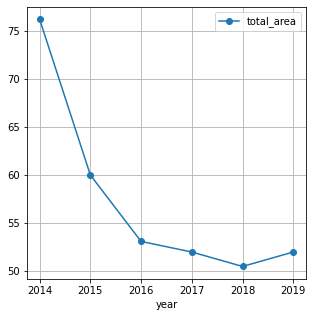

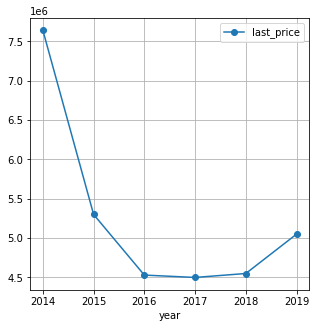

In [65]:
# смотрим зависимость полощади и даты размещения
(
    data.pivot_table(index='year', values='total_area', aggfunc='median')
    .plot(grid=True, style='o-', figsize=(5, 5))
)

(
    data.pivot_table(index='year', values='last_price', aggfunc='median')
    .plot(grid=True, style='o-', figsize=(5, 5))
)

Площадь объектов снижалась до 2018 года, а потом начала расти, а вместе с площадью и цена на квартиры также падала

**4.4 Посчитайте среднюю цену одного квадратного метра в 10 населённых пунктах с наибольшим числом объявлений**

In [66]:
ten_city = data['locality_name'].value_counts().head(10)
ten_city

санкт-петербург      15645
поселок мурино         552
поселок шушары         439
всеволожск             398
пушкин                 369
колпино                338
поселок парголово      327
гатчина                307
деревня кудрово        299
выборг                 237
Name: locality_name, dtype: int64

In [67]:
area_ave_price = (data
                  .query('locality_name in (@ten_city.index)')
                  .pivot_table(values='price_area', index='locality_name')
                 )
area_ave_price.sort_values('price_area', ascending=False)

,price_area
locality_name,
санкт-петербург,114840.090372
пушкин,103125.819291
деревня кудрово,92473.547576
поселок парголово,90175.913458
поселок мурино,85629.568678
поселок шушары,78551.344545
колпино,75424.579098
гатчина,68746.146763
всеволожск,68654.473986


In [68]:
data.groupby('locality_name').agg({'balcony':'count', 'last_price':'median'}) \
    .sort_values(by = 'balcony', ascending = False) \
    .head(10)

,balcony,last_price
locality_name,,
санкт-петербург,15645,5500000.0
поселок мурино,552,3400000.0
поселок шушары,439,3950000.0
всеволожск,398,3450000.0
пушкин,369,5180000.0
колпино,338,3600000.0
поселок парголово,327,4100000.0
гатчина,307,3100000.0
деревня кудрово,299,3790000.0


**Выделите населённые пункты с самой высокой и низкой стоимостью квадратного метра**

Самая высокая стоимость квадратного метра в Санкт-Петербурге, затем в городе Пушкин (возможно из-за хорошей застройки и наличию объектов притяжения), далее пригороды, фактически спальные районы Санкт-Петербурга. Самая низская стоимость квадратного метра в Выборге, скорее всего обусловлено удаленностью от Санкт-Петербурга. 

**4.5 Как стоимость объектов зависит от расстояния до центра города**

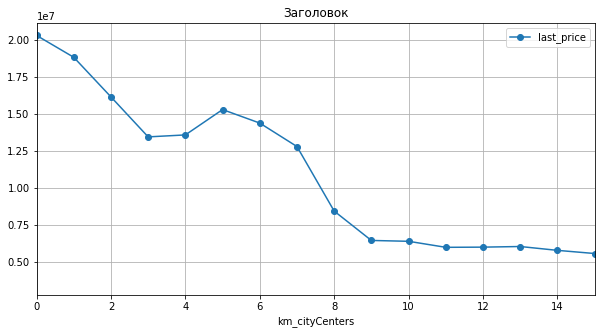

In [69]:
# делаем срез, выбираем Санкт-Петербург и строим сводную таблицу и график, 
# где указана средняя стоимость для каждого км
(
    data.query('locality_name == "санкт-петербург"')
    .pivot_table(index='km_cityCenters', values='last_price')
    .plot(grid=True, style='o-', xlim=(0,15), figsize=(10, 5), title = 'Заголовок')
);


Максимальная стоимость квартир в районе до 5 км от центра, далее снижается до 9 км и после практически не меняется

### Общий вывод

Входные данные были получены от сервиса Яндекс Недвижимость и включали архив объявлений за несколько лет о продаже квартир в Санкт-Петербурге и соседних населённых пунктах. 
Задачей было выполнить предобработку данных и изучить их, чтобы найти особенности и зависимости, которые существуют на рынке недвижимости.

**На первом этапе** было преведено общее изучение данных и их переработка. Так были обработаны и удалены или заменены пропущенные значения. Также изменены типы данных и обработаны дубликаты в данных. Далее были выявлены и обработаны аномальные значения. Кроме того для дальнейшего анализа было необходимо добавить новые столбцы. 

**Следующим этапом стал исследовательский анализ.** Для поиска зависимостей были построены сводные таблицы и графики, а также проанализированы полученные данные. Была изучены факторы, влияющие на стоимость объектов, срок их продажи и стоимость квадратного метра.

В результате были выявлены следующие зависимости:

1. Срок продажи квартиры
    * В среднем квартиру продают за 95 дней. Самыми быстрыми продажами можно считать срок до 45 дней, долгой - от 230 дней (7,5 месяца).
    * Есть много квартир, которые продали за несколько дней после публикации.
    * Также есть объекты, которые продавались несколько десятков месяцев. 


2. Факторы, влияющие на стоимость
    * На стоимость больше всего влияет площадь квартиры, в том числе жилая площадь и площадь кухни. Меньше влияет число комнат, т.е могут быть дорогие квартиры с маленьким кол-вом комнат. 
    * Первый этаж дешевле остальных вариантов, а самые дорогие квартиры на последних этажах.
    * Дороже всего квартиры, опубликованные во вторник и продающиеся в апреле, дешевле всего - в воскресенье и выставленные в июне. Сильно стоимость упала в 2016-2018 годах, с 2019 года цены снова стали повышаться.


3. Стоимость квадратного метра в топ-10 населённых пунктов
    * Дороже всего в Санкт-Петербурге = 114 848
    * Дешевле всего в Выборге = 58 141
    
    
4. Зависимость стоимости от расстояния до центра города
    * Дорогие квартиры распологаются в районе до 5 км от центра Санкт-Петербурга